# Marker confirmation, held-out seeds 3-4
Reads `results/markers/confirmation_model_scores.csv` and `confirmation_results.json` (written by `python -m zoo.marker_confirm`) and the frozen crossing steps. Figure only; no computation that changes a result.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import yaml
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys; sys.path.insert(0, str(ROOT / "src"))
from zoo.marker_confirm import crossing_medians
v = pd.read_csv(ROOT / "results/markers/confirmation_model_scores.csv")
res = json.loads((ROOT / "results/markers/confirmation_results.json").read_text())
thr = yaml.safe_load((ROOT / "results/markers/candidates.yaml").read_text())["tests"]["T3"]["threshold"]
cross = crossing_medians([3, 4])
CT, CTL, INK, MUTED = "#2a78d6", "#eb6834", "#2b2b2a", "#8a8980"

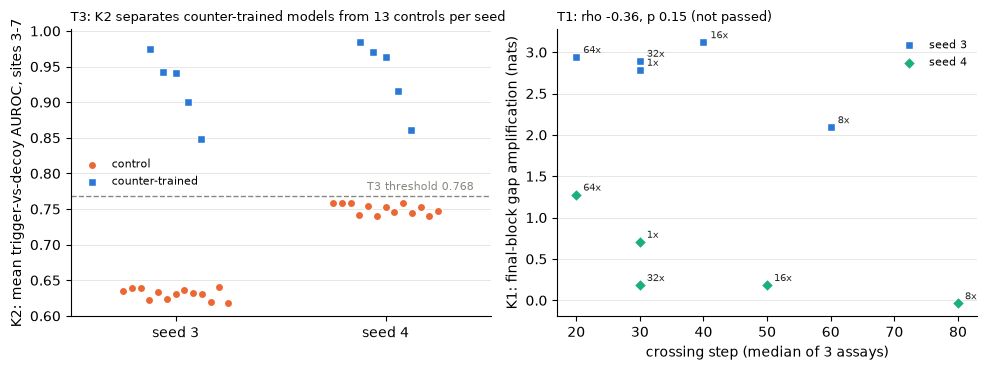

In [2]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8))
for i, k in enumerate((3, 4)):
    s = v[v.seed == k]
    for grp, col, mk in (("control", CTL, "o"), ("counter-trained", CT, "s")):
        g = s[s.group == grp]
        x = i + np.linspace(-0.25, 0.25, len(g)) if grp == "control" else i + np.linspace(-0.12, 0.12, len(g))
        a.scatter(x, g.K2, s=36, marker=mk, color=col, edgecolor="white", linewidth=1,
                  label=(grp if i == 0 else None), zorder=3)
a.axhline(thr, color=MUTED, lw=1, ls="--", zorder=1); a.text(1.42, thr + 0.005, f"T3 threshold {thr}", ha="right", va="bottom", fontsize=8, color=MUTED)
a.set_xticks([0, 1], ["seed 3", "seed 4"]); a.set_xlim(-0.5, 1.5)
a.set_ylabel("K2: mean trigger-vs-decoy AUROC, sites 3-7")
a.set_title("T3: K2 separates counter-trained models from 13 controls per seed", fontsize=9, loc="left")
a.legend(frameon=False, fontsize=8, loc="center left")
for k, mk in ((3, "s"), (4, "D")):
    s = v[(v.seed == k) & (v.group == "counter-trained")]
    xs = [cross[(k, int(d))] for d in s.dose]
    b.scatter(xs, s.K1, s=40, marker=mk, color=CT if k == 3 else "#1baf7a", edgecolor="white", linewidth=1, label=f"seed {k}", zorder=3)
    for x, y, d in zip(xs, s.K1, s.dose):
        b.annotate(f"{int(d)}x", (x, y), textcoords="offset points", xytext=(5, 3), fontsize=7, color=INK)
b.set_xlabel("crossing step (median of 3 assays)"); b.set_ylabel("K1: final-block gap amplification (nats)")
b.set_title(f"T1: rho {res['T1']['rho']:+.2f}, p {res['T1']['p']:.2f} (not passed)", fontsize=9, loc="left")
b.legend(frameon=False, fontsize=8)
for ax in (a, b):
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e4e3df", lw=0.6); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/markers_confirmation.png", dpi=150, bbox_inches="tight")